In [2]:
import pandas as pd

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/customer_data.csv")
print(df.shape)
df.head()

(60360, 12)


,Customer_ID,Age,Membership_Years,Total_Spend,Items_Purchased,Number_of_Orders,Average_Rating,Discount_Applied,Days_Since_Last_Purchase,Gender,City,Satisfaction_Level
0,CUST-040638,38.0,5.4,101276.93,63,24,NaN,Yes,1.0,Female,Delhi,High
1,CUST-023144,50.0,0.4,549.48,2,2,3.8,Yes,59.0,M,Chandigarh,Low
2,CUST-005874,18.0,0.8,1161.75,3,3,4.5,No,50.0,Male,Bengaluru,Medium
3,CUST-040308,34.0,5.3,107741.81,94,31,4.2,No,4.0,Male,Pune,High
4,CUST-049092,31.0,7.3,33186.86,29,13,5.0,No,24.0,Male,Jaipur,High


In [3]:
df.info();

<class 'pandas.DataFrame'>
RangeIndex: 60360 entries, 0 to 60359
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               60360 non-null  str    
 1   Age                       59422 non-null  float64
 2   Membership_Years          60360 non-null  float64
 3   Total_Spend               60360 non-null  float64
 4   Items_Purchased           60360 non-null  int64  
 5   Number_of_Orders          60360 non-null  int64  
 6   Average_Rating            59136 non-null  float64
 7   Discount_Applied          60360 non-null  str    
 8   Days_Since_Last_Purchase  60360 non-null  float64
 9   Gender                    60360 non-null  str    
 10  City                      60360 non-null  str    
 11  Satisfaction_Level        59258 non-null  str    
dtypes: float64(5), int64(2), str(5)
memory usage: 7.3 MB


In [4]:
df.describe().round(1)

,Age,Membership_Years,Total_Spend,Items_Purchased,Number_of_Orders,Average_Rating,Days_Since_Last_Purchase
count,59422.0,60360.0,60360.0,60360.0,60360.0,59136.0,60360.0
mean,34.3,3.0,35037.3,31.7,13.1,3.8,59.1
std,12.3,2.8,52392.3,27.9,8.9,0.6,58.9
min,-1.0,0.1,186.8,1.0,1.0,1.1,1.0
25%,26.0,1.0,5593.6,9.0,6.0,3.4,17.0
50%,33.0,2.1,16636.4,26.0,12.0,3.8,37.0
75%,42.0,4.1,36311.3,40.0,17.0,4.2,82.0
max,999.0,15.0,1625517.4,170.0,53.0,5.0,365.0


In [5]:
missing = df.isna().sum()
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})

,missing,percent
Customer_ID,0,0.00
Age,938,1.55
Membership_Years,0,0.00
Total_Spend,0,0.00
Items_Purchased,0,0.00
Number_of_Orders,0,0.00
Average_Rating,1224,2.03
Discount_Applied,0,0.00
Days_Since_Last_Purchase,0,0.00
Gender,0,0.00


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["Customer_ID"].duplicated().sum())

Duplicate rows: 360
Duplicate IDs: 360


In [7]:
for col in ["Gender", "City", "Discount_Applied", "Satisfaction_Level"]:
    print(df[col].value_counts(dropna=False), "\n")

Gender
Female    28327
Male      27878
Other      1740
F           930
M           912
male        573
Name: count, dtype: int64 

City
Mumbai          7392
Delhi           7344
Bengaluru       6804
Hyderabad       5562
Chennai         5021
Pune            4915
Kolkata         4257
Ludhiana        3789
Ahmedabad       3687
Chandigarh      3664
Lucknow         3107
Jaipur          3075
DELHI            120
 Mumbai          117
BENGALURU        110
 Bengaluru       105
MUMBAI            99
 Delhi            89
HYDERABAD         86
 Chennai          77
 Hyderabad        75
PUNE              71
CHENNAI           70
KOLKATA           69
 Chandigarh       64
 Lucknow          61
 Pune             60
 Kolkata          58
AHMEDABAD         55
CHANDIGARH        55
 Ahmedabad        53
 Ludhiana         53
LUDHIANA          52
 Jaipur           51
LUCKNOW           50
JAIPUR            43
Name: count, dtype: int64 

Discount_Applied
No     30463
Yes    29897
Name: count, dtype: int64 

Satisfact

In [8]:
invalid_age = (df["Age"] < 18) | (df["Age"] > 100)
print("Invalid ages:", invalid_age.sum())
df.loc[invalid_age, "Age"].value_counts()

Invalid ages: 15


Age
 120.0    5
-1.0      3
 0.0      3
 999.0    2
 150.0    2
Name: count, dtype: int64

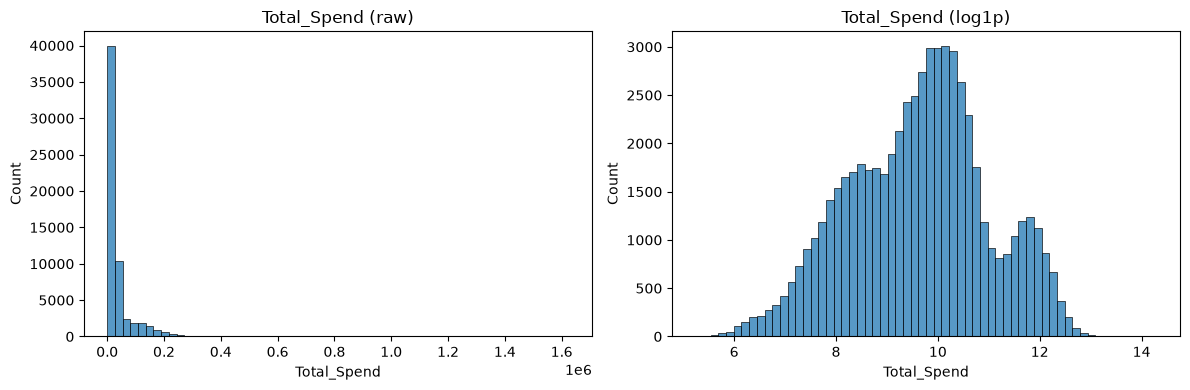

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Total_Spend"], bins=60, ax=axes[0])
axes[0].set_title("Total_Spend (raw)")
sns.histplot(np.log1p(df["Total_Spend"]), bins=60, ax=axes[1])
axes[1].set_title("Total_Spend (log1p)")
plt.tight_layout()
plt.show()

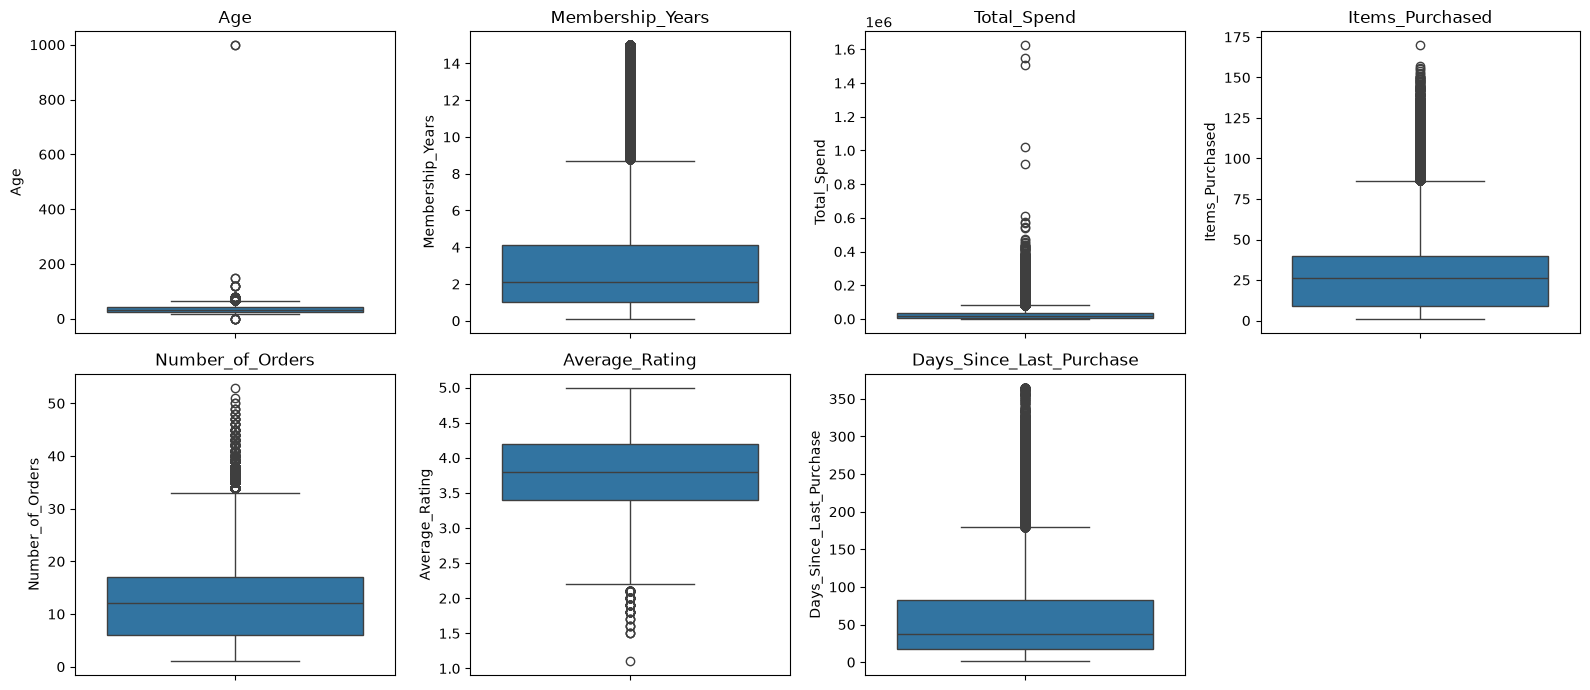

In [10]:
num_cols = ["Age", "Membership_Years", "Total_Spend", "Items_Purchased",
            "Number_of_Orders", "Average_Rating", "Days_Since_Last_Purchase"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [11]:
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:26s} outliers: {n_out:6d} ({n_out / len(df) * 100:.2f}%)")

Age                        outliers:    255 (0.42%)
Membership_Years           outliers:   2947 (4.88%)
Total_Spend                outliers:   7494 (12.42%)
Items_Purchased            outliers:   4626 (7.66%)
Number_of_Orders           outliers:   2146 (3.56%)
Average_Rating             outliers:     97 (0.16%)
Days_Since_Last_Purchase   outliers:   3372 (5.59%)


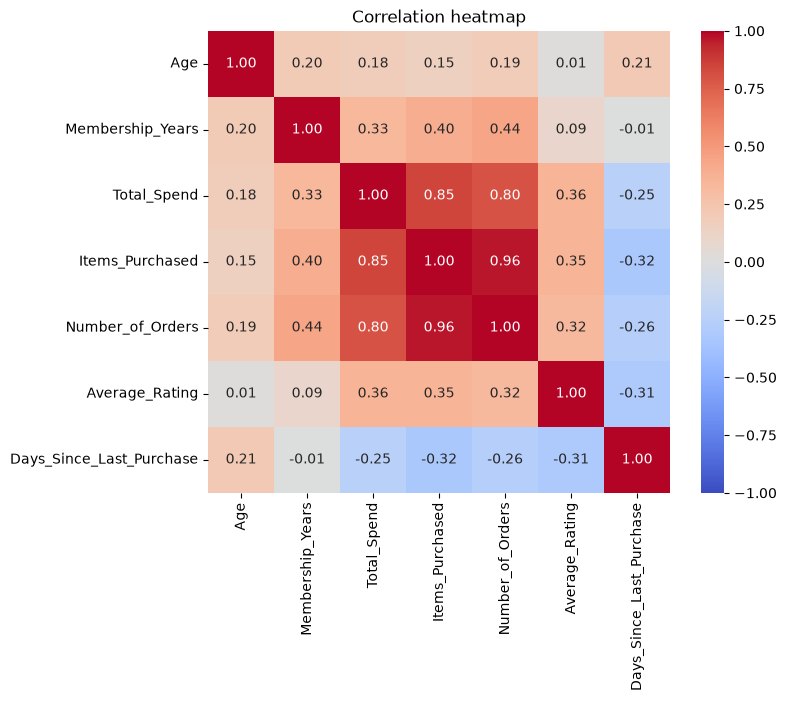

In [12]:
df_tmp = df.copy()
df_tmp.loc[~df_tmp["Age"].between(18, 100), "Age"] = np.nan

corr = df_tmp[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation heatmap")
plt.show()

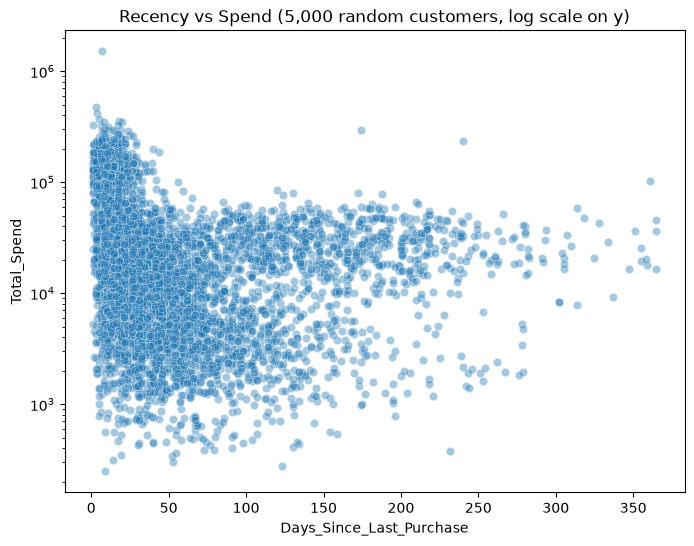

In [13]:
sample = df_tmp.sample(5000, random_state=42)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x="Days_Since_Last_Purchase", y="Total_Spend", alpha=0.4)
plt.yscale("log")
plt.title("Recency vs Spend (5,000 random customers, log scale on y)")
plt.show()

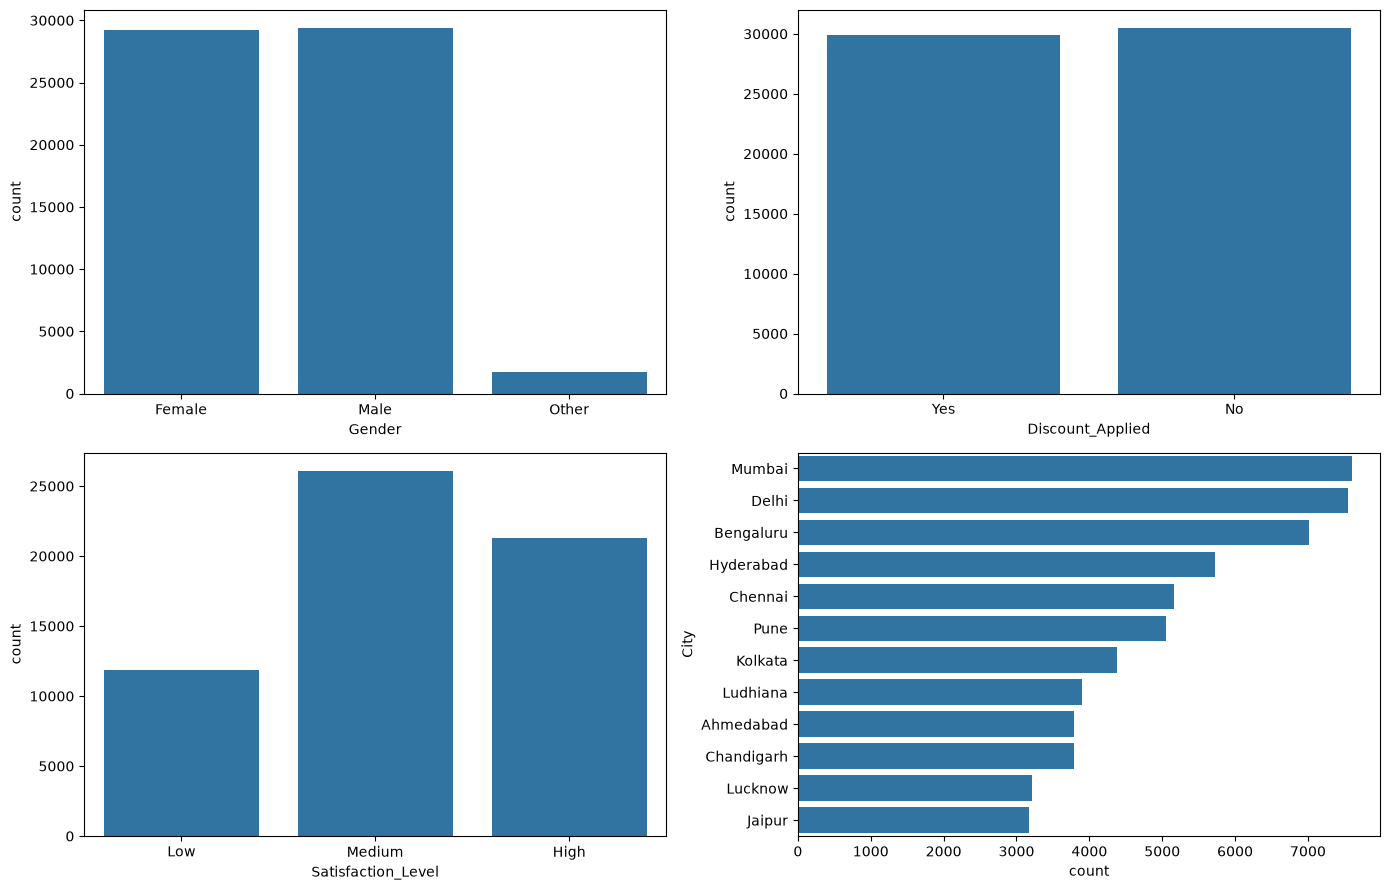

In [14]:
df_tmp["Gender"] = (df_tmp["Gender"].str.strip().str.lower()
                    .map({"male": "Male", "m": "Male", "female": "Female", "f": "Female", "other": "Other"}))
df_tmp["City"] = df_tmp["City"].str.strip().str.title()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(data=df_tmp, x="Gender", ax=axes[0, 0])
sns.countplot(data=df_tmp, x="Discount_Applied", ax=axes[0, 1])
sns.countplot(data=df_tmp, x="Satisfaction_Level", order=["Low", "Medium", "High"], ax=axes[1, 0])
sns.countplot(data=df_tmp, y="City", order=df_tmp["City"].value_counts().index, ax=axes[1, 1])
plt.tight_layout()
plt.show()

In [15]:
print(df_tmp.groupby("Discount_Applied")[["Total_Spend", "Number_of_Orders", "Days_Since_Last_Purchase"]].median().round(1))
print(df_tmp.groupby("Gender")[["Total_Spend", "Number_of_Orders"]].median().round(1))
print(df_tmp.groupby("City")[["Total_Spend"]].median().round(0))

                  Total_Spend  Number_of_Orders  Days_Since_Last_Purchase
Discount_Applied                                                         
No                    23143.3              13.0                      36.0
Yes                   13346.4              11.0                      38.0
        Total_Spend  Number_of_Orders
Gender                               
Female      16876.6              12.0
Male        16354.6              12.0
Other       17329.0              12.0
            Total_Spend
City                   
Ahmedabad       16347.0
Bengaluru       16560.0
Chandigarh      16561.0
Chennai         16454.0
Delhi           16594.0
Hyderabad       16529.0
Jaipur          16379.0
Kolkata         16475.0
Lucknow         16082.0
Ludhiana        16980.0
Mumbai          16923.0
Pune            17294.0


In [16]:
print(df_tmp.groupby("Satisfaction_Level")["Average_Rating"].agg(["median", "mean"]).round(2))

                    median  mean
Satisfaction_Level              
High                   4.3  4.33
Low                    3.2  3.17
Medium                 3.7  3.72


In [ ]:
# Column	Decision	Reason
# Customer_ID	Exclude	Identifier, no behavior
# Gender, City	Exclude	Medians show no behavioral difference, and they risk bias
# Age	Candidate, fix first	15 impossible values, weakly correlated with everything
# Total_Spend	Include, log-transform	Strong right skew
# Number_of_Orders	Include, log-transform	Frequency signal, but correlated 0.96 with Items
# Items_Purchased	Decide	Nearly duplicates Orders (0.96)
# Days_Since_Last_Purchase	Include, log-transform	Recency, right-skewed
# Average_Rating	Include	Engagement and quality signal
# Discount_Applied	Include, as 0/1	Shows behavioral differences
# Satisfaction_Level	Decide	Probably tracks Average_Rating closely
# Membership_Years	Candidate	Tenure, skewed